# AI-Driven Closed-Loop Adaptive Execution Framework for Efficient ERP–Blockchain Integration
## Final reviewer-aligned, leakage-safe, BigQuery REST notebook

**Purpose:** final reproducible experiment for the revised manuscript.

### Main corrections included
1. Direct BigQuery Public Dataset access through the REST API: `tabledata.list` (no query job) when the table is a native table, with automatic fallbacks: a `jobs.query` REST call (if a Google Cloud project ID is provided) or, otherwise, the same Bitcoin block fields (timestamp, tx count, size, weight) downloaded from the public mempool.space / blockstream.info APIs.
2. Robust BigQuery TIMESTAMP parsing.
3. Explicit **non-overlapping 10-minute workload windows**.
4. Causal feature engineering: historical rolling features use past observations only.
5. **Train / Validation / Final Test = 64% / 16% / 20%** chronological split.
6. Model selection uses **validation only**; the final test set is untouched until the final evaluation.
7. Random Forest, Gradient Boosting, MLP, and an LSTM comparator.
8. Automated controller-threshold optimization using validation data only.
9. Thresholds are frozen before the final test.
10. Static, fixed-rule, Q-learning-inspired, and proposed adaptive controller comparisons.
11. Repeated runs, paired tests, effect size, and bootstrap confidence interval.
12. Hybrid-storage saving is reported explicitly as a **trace-driven simulation estimate**, not a physical deployment measurement.
13. `confirmation_latency` is defined as a **block-interarrival latency proxy** derived from the public Bitcoin trace; it is not claimed to be transaction-level confirmation latency.


In [1]:
# ============================================================
# 1) SETUP
# ============================================================

# NOTE: pip install removed on purpose. Colab already ships compatible versions;
# upgrading numpy/pandas here breaks the runtime (ImportError: _slice).

import os
import json
import time
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import auth
auth.authenticate_user()

import google.auth
from google.auth.transport.requests import Request

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import ttest_rel, wilcoxon, levene

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

# -----------------------------
# Experiment configuration
# -----------------------------
DATASET_PROJECT = "bigquery-public-data"
DATASET = "crypto_bitcoin"
TABLE = "blocks"

# OPTIONAL. Leave empty ("") if you have no Google Cloud project: the notebook then
# downloads the same Bitcoin block data from a public API instead.
# If you have one, put its ID here, e.g. "my-project-123456".
BILLING_PROJECT = ""

START_DATE = "2020-01-01"
END_DATE   = "2021-01-01"

WINDOW_MINUTES = 10
TARGET_LATENCY = 600.0

TRAIN_RATIO = 0.64
VAL_RATIO   = 0.16
TEST_RATIO  = 0.20

LOOKBACK_LSTM = 12
RUN_LSTM = True

N_REPEATED_RUNS = 10
N_BOOTSTRAP = 5000

# Controller effect coefficients are deliberately explicit.
# They are simulation coefficients, NOT measured deployment effects.
LATENCY_ACTION_REDUCTION = 0.08
QUEUE_ACTION_REDUCTION = 0.05
STORAGE_ACTION_REDUCTION = 0.04
MAX_POLICY_REDUCTION = 0.15

print("Setup complete.")
print("Target latency:", TARGET_LATENCY, "seconds")
print("Window:", WINDOW_MINUTES, "minutes")
print("Split:", TRAIN_RATIO, TRAIN_RATIO + VAL_RATIO, TEST_RATIO)


Setup complete.
Target latency: 600.0 seconds
Window: 10 minutes
Split: 0.64 0.8 0.2


In [2]:
# ============================================================
# 2) BIGQUERY PUBLIC TABLE ACCESS (REST)
#    Path A: tabledata.list  (no query job)  -> used when the table is a native TABLE
#    Path B: jobs.query REST (filtered to the study period) -> automatic fallback,
#            used when Path A is impossible/fails (e.g. the table is now a VIEW) AND BILLING_PROJECT is set
#    Path C: public Bitcoin block APIs (mempool.space / blockstream.info) -> used when no
#            Google Cloud project is available. Same Bitcoin blocks, no login needed.
# ============================================================

import re
from concurrent.futures import ThreadPoolExecutor

BASE = "https://bigquery.googleapis.com/bigquery/v2"

def _valid_project(p):
    p = (p or "").strip()
    return bool(p) and not p.upper().startswith("YOUR") and \
           re.fullmatch(r"[a-z][a-z0-9\-.:]{4,}[a-z0-9]", p) is not None

def get_bigquery_credentials():
    credentials, project = google.auth.default(
        scopes=["https://www.googleapis.com/auth/cloud-platform"]
    )
    if not credentials.valid:
        credentials.refresh(Request())
    return credentials, project

credentials, default_project = get_bigquery_credentials()

TABLE_METADATA_URL = f"{BASE}/projects/{DATASET_PROJECT}/datasets/{DATASET}/tables/{TABLE}"
TABLE_DATA_URL = TABLE_METADATA_URL + "/data"

session = requests.Session()
session.headers.update({"Authorization": f"Bearer {credentials.token}"})

def check(resp, what):
    """Raise an error that includes Google's real explanation (the response body)."""
    if not resp.ok:
        raise RuntimeError(f"{what} failed: HTTP {resp.status_code}\n{resp.text[:1500]}")
    return resp

# ---------- table metadata (diagnostic) ----------
metadata = {}
try:
    metadata = check(session.get(TABLE_METADATA_URL, timeout=60), "Table metadata").json()
except Exception as e:
    print("Could not read table metadata:", e)

total_rows = int(metadata.get("numRows", 0) or 0)
table_type = metadata.get("type", "UNKNOWN")

print("BigQuery table:", f"{DATASET_PROJECT}.{DATASET}.{TABLE}")
print("Table type:", table_type)
print("Rows reported by table metadata:", total_rows)
print("Requires partition filter:", metadata.get("requirePartitionFilter", False))

def parse_bigquery_timestamp_series(series):
    # BigQuery TIMESTAMP can arrive as INT64 microseconds when
    # useInt64Timestamp=True is requested. Handle numeric and
    # string representations robustly.
    numeric = pd.to_numeric(series, errors="coerce")

    if numeric.notna().mean() > 0.95:
        med = float(numeric.dropna().abs().median())
        if med > 1e14:
            return pd.to_datetime(numeric, unit="us", utc=True, errors="coerce")
        elif med > 1e11:
            return pd.to_datetime(numeric, unit="ms", utc=True, errors="coerce")
        else:
            return pd.to_datetime(numeric, unit="s", utc=True, errors="coerce")

    return pd.to_datetime(series, utc=True, errors="coerce")

def _rows_to_dicts(payload, rows):
    schema_names = [f["name"] for f in payload.get("schema", {}).get("fields", [])]
    for row in payload.get("rows", []):
        values = [cell.get("v") for cell in row.get("f", [])]
        if len(values) == len(schema_names):
            rows.append(dict(zip(schema_names, values)))

# ---------- Path A: tabledata.list ----------
def fetch_via_tabledata():
    rows, page_token, page = [], None, 0
    while True:
        params = {
            "maxResults": 100000,
            "selectedFields": "timestamp,transaction_count,size,weight",
            "formatOptions.useInt64Timestamp": "true",
        }
        if page_token:
            params["pageToken"] = page_token
        payload = check(session.get(TABLE_DATA_URL, params=params, timeout=120),
                        "tabledata.list").json()
        _rows_to_dicts(payload, rows)
        page += 1
        print(f"Page {page}: collected {len(rows):,} rows")
        page_token = payload.get("pageToken")
        if not page_token:
            break
    return pd.DataFrame(rows)

# ---------- Path B: jobs.query (REST) ----------
def fetch_via_query():
    project = BILLING_PROJECT if _valid_project(BILLING_PROJECT) else default_project

    sql = f"""
        SELECT `timestamp`, transaction_count, size, weight
        FROM `{DATASET_PROJECT}.{DATASET}.{TABLE}`
        WHERE timestamp_month >= DATE_TRUNC(DATE '{START_DATE}', MONTH)
          AND timestamp_month <= DATE '{END_DATE}'
          AND `timestamp` >= TIMESTAMP '{START_DATE}'
          AND `timestamp` <  TIMESTAMP '{END_DATE}'
        ORDER BY `timestamp`
    """
    body = {
        "query": sql,
        "useLegacySql": False,
        "location": "US",
        "timeoutMs": 60000,
        "maxResults": 100000,
        "formatOptions": {"useInt64Timestamp": True},
    }
    print(f"Running jobs.query in project '{project}' ...")
    resp = check(session.post(f"{BASE}/projects/{project}/queries", json=body, timeout=180),
                 "jobs.query").json()
    job = resp["jobReference"]
    results_url = f"{BASE}/projects/{project}/queries/{job['jobId']}"
    base_params = {
        "location": job.get("location", "US"),
        "maxResults": 100000,
        "formatOptions.useInt64Timestamp": "true",
    }

    while not resp.get("jobComplete", False):
        time.sleep(2)
        resp = check(session.get(results_url, params=base_params, timeout=180),
                     "getQueryResults").json()

    rows, page = [], 0
    while True:
        _rows_to_dicts(resp, rows)
        page += 1
        print(f"Page {page}: collected {len(rows):,} rows")
        token = resp.get("pageToken")
        if not token:
            break
        resp = check(session.get(results_url, params={**base_params, "pageToken": token},
                                 timeout=180), "getQueryResults").json()
    return pd.DataFrame(rows)

# ---------- Path C: public Bitcoin block APIs (no Google Cloud project needed) ----------
def _download_from_provider(name, blocks_url, tip_url, page):
    s = requests.Session()
    s.headers.update({"User-Agent": "Mozilla/5.0 (research-notebook)"})

    def get(url, as_json=True, tries=8):
        err = None
        for k in range(tries):
            try:
                r = s.get(url, timeout=30)
                if r.status_code == 200:
                    return r.json() if as_json else r.text
                err = f"HTTP {r.status_code} {r.text[:150]}"
            except Exception as e:
                err = repr(e)
            time.sleep(min(2 * (k + 1), 20))   # back off (also handles 429 rate limits)
        raise RuntimeError(f"{url} -> {err}")

    def get_blocks(h):
        return get(f"{blocks_url}/{h}")        # up to `page` blocks, descending from height h

    def first_height_at_or_after(ts, lo, hi):
        while lo < hi:
            mid = (lo + hi) // 2
            b = next(x for x in get_blocks(mid) if x["height"] == mid)
            if int(b["timestamp"]) < ts:
                lo = mid + 1
            else:
                hi = mid
        return lo

    tip = int(get(tip_url, as_json=False).strip())
    start_ts = int(pd.Timestamp(START_DATE, tz="UTC").timestamp())
    end_ts   = int(pd.Timestamp(END_DATE,   tz="UTC").timestamp())

    start_h = first_height_at_or_after(start_ts, 300000, tip) - 40   # small safety margin;
    end_h   = min(first_height_at_or_after(end_ts, 300000, tip) + 40, tip)  # cell 3 filters exactly
    print(f"{name}: tip={tip:,} | downloading heights {start_h:,} to {end_h:,} "
          f"({end_h - start_h + 1:,} blocks)")

    store = {}
    def work(h):
        for b in get_blocks(h):
            store[b["height"]] = b

    starts = list(range(end_h, start_h - 1, -page))
    with ThreadPoolExecutor(max_workers=4) as ex:
        for i, _ in enumerate(ex.map(work, starts), 1):
            if i % 250 == 0 or i == len(starts):
                print(f"  requests {i:,}/{len(starts):,} | blocks {len(store):,}")

    # fill any gaps (in case a page returned fewer blocks than expected)
    for _ in range(2000):
        missing = [h for h in range(start_h, end_h + 1) if h not in store]
        if not missing:
            break
        work(max(missing))
    else:
        print("WARNING: some heights are still missing.")

    rows = [
        {"timestamp": b["timestamp"], "transaction_count": b["tx_count"],
         "size": b["size"], "weight": b["weight"]}
        for h, b in sorted(store.items()) if start_h <= h <= end_h
    ]
    return pd.DataFrame(rows)

def fetch_via_public_api():
    cache = f"/content/btc_blocks_{START_DATE}_{END_DATE}.csv"
    if os.path.exists(cache):
        print("Loading cached blocks from", cache)
        return pd.read_csv(cache)

    providers = [
        ("mempool.space",    "https://mempool.space/api/v1/blocks", "https://mempool.space/api/blocks/tip/height", 15),
        ("blockstream.info", "https://blockstream.info/api/blocks", "https://blockstream.info/api/blocks/tip/height", 10),
    ]
    last_err = None
    for name, blocks_url, tip_url, page in providers:
        try:
            print(f"\nPublic API provider: {name}")
            out = _download_from_provider(name, blocks_url, tip_url, page)
            if len(out) > 0:
                try:
                    out.to_csv(cache, index=False)
                except Exception:
                    pass
                return out
        except Exception as e:
            last_err = e
            print(f"{name} failed: {e}")
    raise RuntimeError(f"All public API providers failed. Last error: {last_err}")

# ---------- choose path ----------
raw = pd.DataFrame()

if table_type == "TABLE" and total_rows > 0:
    try:
        print("\nPath A: tabledata.list ...")
        raw = fetch_via_tabledata()
    except Exception as e:
        print("\nPath A failed:\n", e)
else:
    print(f"\nPath A skipped (type={table_type}, numRows={total_rows}); "
          "tabledata.list only works on native tables with data.")

if raw.empty and (_valid_project(BILLING_PROJECT) or default_project):
    try:
        print("\nPath B: jobs.query ...")
        raw = fetch_via_query()
    except Exception as e:
        print("\nPath B failed:\n", e)

if raw.empty:
    print("\nPath C: public Bitcoin block API (no Google Cloud project needed) ...")
    raw = fetch_via_public_api()

if raw.empty:
    raise RuntimeError("No rows were returned from any data source.")

print("\nRaw rows downloaded:", len(raw))
display(raw.head())
print(raw.dtypes)


BigQuery table: bigquery-public-data.crypto_bitcoin.blocks
Table type: VIEW
Rows reported by table metadata: 0
Requires partition filter: False

Path A skipped (type=VIEW, numRows=0); tabledata.list only works on native tables with data.

Path C: public Bitcoin block API (no Google Cloud project needed) ...

Public API provider: mempool.space
mempool.space: tip=967,809 | downloading heights 610,651 to 663,953 (53,303 blocks)
  requests 250/3,554 | blocks 3,750
  requests 500/3,554 | blocks 7,725
  requests 750/3,554 | blocks 11,400
  requests 1,000/3,554 | blocks 15,015
  requests 1,250/3,554 | blocks 23,370
  requests 1,500/3,554 | blocks 23,370
  requests 1,750/3,554 | blocks 26,370
  requests 2,000/3,554 | blocks 30,180
  requests 2,250/3,554 | blocks 33,930
  requests 2,500/3,554 | blocks 37,800
  requests 2,750/3,554 | blocks 41,430
  requests 3,000/3,554 | blocks 50,685
  requests 3,250/3,554 | blocks 50,685
  requests 3,500/3,554 | blocks 52,500
  requests 3,554/3,554 | blocks 5

,timestamp,transaction_count,size,weight
0,1577814281,2145,1303918,3993298
1,1577815268,2493,1160959,3993553
2,1577816206,2558,1261622,3993584
3,1577817464,3195,1312876,3993040
4,1577818035,2956,1358327,3993368


timestamp            int64
transaction_count    int64
size                 int64
weight               int64
dtype: object


In [3]:
# ============================================================
# 3) CLEANING + 2020 TRACE FILTER
# ============================================================

required_cols = ["timestamp", "transaction_count", "size", "weight"]
missing = [c for c in required_cols if c not in raw.columns]

if missing:
    raise ValueError(f"Missing required BigQuery columns: {missing}")

df = raw.copy()

df["block_timestamp"] = parse_bigquery_timestamp_series(df["timestamp"])

for c in ["transaction_count", "size", "weight"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=[
    "block_timestamp",
    "transaction_count",
    "size",
    "weight"
]).copy()

df = df[
    (df["block_timestamp"] >= pd.Timestamp(START_DATE, tz="UTC")) &
    (df["block_timestamp"] <  pd.Timestamp(END_DATE, tz="UTC"))
].copy()

df = (
    df.sort_values("block_timestamp")
      .drop_duplicates(subset=["block_timestamp"])
      .reset_index(drop=True)
)

print("2020 blocks:", len(df))
print("Date range:",
      df["block_timestamp"].min(),
      "to",
      df["block_timestamp"].max())

if len(df) < 1000:
    raise RuntimeError(
        "Too few 2020 rows were recovered. "
        "Do not proceed to manuscript results until this is fixed."
    )

display(df.head())
display(df.tail())


2020 blocks: 53198
Date range: 2020-01-01 00:03:05+00:00 to 2020-12-31 23:57:27+00:00


,timestamp,transaction_count,size,weight,block_timestamp
0,1577836985,2500,1250129,3993629,2020-01-01 00:03:05+00:00
1,1577837252,1840,661706,1934741,2020-01-01 00:07:32+00:00
2,1577837614,1105,436344,1289973,2020-01-01 00:13:34+00:00
3,1577837940,982,467181,1324209,2020-01-01 00:19:00+00:00
4,1577839052,2881,1123752,3399753,2020-01-01 00:37:32+00:00


,timestamp,transaction_count,size,weight,block_timestamp
53193,1609456820,872,1135401,3993219,2020-12-31 23:20:20+00:00
53194,1609457622,1382,1361068,3999397,2020-12-31 23:33:42+00:00
53195,1609458071,1098,1324357,3993250,2020-12-31 23:41:11+00:00
53196,1609458502,1483,1149456,3993360,2020-12-31 23:48:22+00:00
53197,1609459047,2126,1272042,3993534,2020-12-31 23:57:27+00:00


In [4]:
# ============================================================
# 4) CAUSAL BLOCK INTERVAL + 10-MINUTE WORKLOAD WINDOWS
# ============================================================

df["prev_block_timestamp"] = df["block_timestamp"].shift(1)

df["block_time"] = (
    df["block_timestamp"] - df["prev_block_timestamp"]
).dt.total_seconds()

# Remove impossible / extreme intervals before aggregation.
df.loc[
    (df["block_time"] <= 0) | (df["block_time"] > 24 * 3600),
    "block_time"
] = np.nan

df["window_start"] = df["block_timestamp"].dt.floor(
    f"{WINDOW_MINUTES}min"
)

# Non-overlapping temporal windows.
windows = (
    df.groupby("window_start", sort=True)
      .agg(
          transaction_count=("transaction_count", "sum"),
          size=("size", "sum"),
          weight=("weight", "sum"),
          block_count=("block_timestamp", "count"),
          confirmation_latency=("block_time", "mean"),
          latency_std=("block_time", "std"),
          max_block_time=("block_time", "max")
      )
      .reset_index()
)

# A target window must contain enough observations to estimate
# an inter-block interval.
windows = windows[
    (windows["block_count"] >= 2) &
    windows["confirmation_latency"].notna()
].copy()

windows = windows.sort_values("window_start").reset_index(drop=True)

print("10-minute windows:", len(windows))
print("Usable windows:", len(windows))
display(windows.head())


10-minute windows: 14240
Usable windows: 14240


,window_start,transaction_count,size,weight,block_count,confirmation_latency,latency_std,max_block_time
0,2020-01-01 00:00:00+00:00,4340,1911835,5928370,2,267.0,NaN,267.0
1,2020-01-01 00:10:00+00:00,2087,903525,2614182,2,344.0,25.455844,362.0
2,2020-01-01 00:30:00+00:00,2882,1124118,3401217,2,574.0,760.846897,1112.0
3,2020-01-01 00:40:00+00:00,1287,542338,1638772,2,187.0,90.509668,251.0
4,2020-01-01 00:50:00+00:00,2146,724032,2178924,2,370.5,118.086832,454.0


In [5]:
# ============================================================
# 5) TEMPORAL / WORKLOAD FEATURES
#    All historical rolling features use PAST windows only.
# ============================================================

w = windows.copy()

w["hour"] = w["window_start"].dt.hour
w["dayofweek"] = w["window_start"].dt.dayofweek

# Past-only workload history
w["tx_ma_5"] = w["transaction_count"].shift(1).rolling(5).mean()
w["tx_std_5"] = w["transaction_count"].shift(1).rolling(5).std()

w["size_ma_5"] = w["size"].shift(1).rolling(5).mean()
w["weight_ma_5"] = w["weight"].shift(1).rolling(5).mean()

# Past-only latency history
w["prev_block_time"] = w["confirmation_latency"].shift(1)

w["prev_block_time_ma_3"] = (
    w["confirmation_latency"].shift(1).rolling(3).mean()
)

w["prev_block_time_std_3"] = (
    w["confirmation_latency"].shift(1).rolling(3).std()
)

# Workload evolution
w["tx_pct_change"] = (
    w["transaction_count"]
    .pct_change()
    .replace([np.inf, -np.inf], np.nan)
)

w["weight_pct_change"] = (
    w["weight"]
    .pct_change()
    .replace([np.inf, -np.inf], np.nan)
)

# Keep raw pressure components; normalization is performed
# ONLY after the chronological split using training statistics.
w["queue_tx_raw"] = w["transaction_count"]
w["queue_weight_raw"] = w["weight"]

# Rolling payload is a workload/storage-pressure proxy.
w["payload_roll_6"] = (
    w["size"].rolling(6, min_periods=1).sum()
)

w["burst_raw"] = w["transaction_count"]

w = w.dropna().reset_index(drop=True)

print("Usable feature windows:", len(w))


Usable feature windows: 14235


In [6]:
# ============================================================
# 6) CHRONOLOGICAL 64/16/20 SPLIT
# ============================================================

n = len(w)

train_end = int(n * TRAIN_RATIO)
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

train_df = w.iloc[:train_end].copy()
val_df   = w.iloc[train_end:val_end].copy()
test_df  = w.iloc[val_end:].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Final Test:", len(test_df))

print("\nTrain dates:",
      train_df["window_start"].min(),
      "→",
      train_df["window_start"].max())

print("Validation dates:",
      val_df["window_start"].min(),
      "→",
      val_df["window_start"].max())

print("Test dates:",
      test_df["window_start"].min(),
      "→",
      test_df["window_start"].max())

assert len(train_df) + len(val_df) + len(test_df) == len(w)
assert train_df["window_start"].max() < val_df["window_start"].min()
assert val_df["window_start"].max() < test_df["window_start"].min()


Train: 9110
Validation: 2278
Final Test: 2847

Train dates: 2020-01-01 02:10:00+00:00 → 2020-08-21 15:30:00+00:00
Validation dates: 2020-08-21 15:50:00+00:00 → 2020-10-17 20:10:00+00:00
Test dates: 2020-10-17 20:30:00+00:00 → 2020-12-31 23:40:00+00:00


In [7]:
# ============================================================
# 7) TRAIN-ONLY NORMALIZATION / BURST / PRESSURE DEFINITIONS
# ============================================================

# Training statistics only.
tx_max_train = max(train_df["queue_tx_raw"].max(), 1.0)
weight_max_train = max(train_df["queue_weight_raw"].max(), 1.0)

burst_mean_train = train_df["burst_raw"].mean()
burst_std_train = train_df["burst_raw"].std()

burst_threshold = burst_mean_train + burst_std_train

# Queue pressure in [0,1], based only on training maxima.
for part in [train_df, val_df, test_df]:
    part["queue_pressure"] = (
        0.5 * (part["queue_tx_raw"] / tx_max_train) +
        0.5 * (part["queue_weight_raw"] / weight_max_train)
    ).clip(0, 1)

    part["burst_flag"] = (
        part["burst_raw"] > burst_threshold
    ).astype(int)

# Storage pressure is a rolling payload/workload proxy.
# The normalization reference is training-only.
storage_reference = max(
    float(train_df["payload_roll_6"].quantile(0.95)),
    1.0
)

for part in [train_df, val_df, test_df]:
    part["storage_pressure"] = (
        part["payload_roll_6"] / storage_reference
    ).clip(lower=0, upper=1.5)

print("Training-only burst threshold:", burst_threshold)
print("Training-only storage reference:", storage_reference)


Training-only burst threshold: 6523.288740873858
Training-only storage reference: 21545152.15


In [8]:
# ============================================================
# 8) FEATURE MATRIX
# ============================================================

feature_cols = [
    "transaction_count",
    "size",
    "weight",
    "hour",
    "dayofweek",
    "tx_ma_5",
    "tx_std_5",
    "size_ma_5",
    "weight_ma_5",
    "prev_block_time",
    "prev_block_time_ma_3",
    "prev_block_time_std_3",
    "burst_flag",
    "queue_pressure",
    "tx_pct_change",
    "weight_pct_change"
]

target_col = "confirmation_latency"

X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

print("Feature count:", len(feature_cols))
print("Target:", target_col)


Feature count: 16
Target: confirmation_latency


In [10]:
# ============================================================
# 9) MODEL DEFINITIONS
# ============================================================

def make_models(seed=42):
    return {
        "RandomForest": RandomForestRegressor(
            n_estimators=300,
            max_depth=12,
            min_samples_split=5,
            random_state=seed,
            n_jobs=-1
        ),

        "GradientBoosting": GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.03,
            max_depth=3,
            random_state=seed
        ),

        "MLP": MLPRegressor(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            learning_rate_init=0.0008,
            max_iter=700,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=25,
            random_state=seed
        )
    }

def regression_metrics(y_true, pred):
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "R2": r2_score(y_true, pred)
    }

models = make_models(SEED)


In [11]:
# ============================================================
# 10) VALIDATION-ONLY MODEL SELECTION
#     THE FINAL TEST SET IS NOT USED HERE.
# ============================================================

train_scaler = StandardScaler()
X_train_scaled = train_scaler.fit_transform(X_train)
X_val_scaled = train_scaler.transform(X_val)

validation_results = []
validation_predictions = {}
trained_validation_models = {}

for name, model in models.items():

    if name == "MLP":
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_val_scaled)
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_val)

    metrics = regression_metrics(y_val, pred)

    validation_predictions[name] = pred
    trained_validation_models[name] = model

    validation_results.append({
        "Model": name,
        **metrics
    })

validation_df = (
    pd.DataFrame(validation_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(validation_df)

best_model_name = validation_df.iloc[0]["Model"]

print("\nSelected model from validation ONLY:", best_model_name)
print("The final test set has not been used for model selection.")


,Model,MAE,RMSE,R2
0,MLP,159.726982,229.065191,0.361380
1,RandomForest,159.701106,230.844166,0.351422
2,GradientBoosting,161.180393,230.969499,0.350718



Selected model from validation ONLY: MLP
The final test set has not been used for model selection.


In [12]:
# ============================================================
# 11) OPTIONAL LSTM COMPARATOR
#     Validation-based selection; test remains untouched.
# ============================================================

lstm_validation_pred = None
lstm_model = None
lstm_scaler = None

if RUN_LSTM:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping

    tf.random.set_seed(SEED)

    lstm_scaler = StandardScaler()
    X_all_for_lstm = pd.concat([X_train, X_val], axis=0)

    # Fit scaler on training only.
    lstm_scaler.fit(X_train)

    X_train_lstm_scaled = lstm_scaler.transform(X_train)
    X_val_lstm_scaled = lstm_scaler.transform(X_val)

    def make_sequences(X_arr, y_arr, lookback):
        X_seq, y_seq = [], []
        for i in range(lookback, len(X_arr)):
            X_seq.append(X_arr[i-lookback:i])
            y_seq.append(y_arr[i])
        return np.asarray(X_seq), np.asarray(y_seq)

    Xtr_seq, ytr_seq = make_sequences(
        X_train_lstm_scaled,
        y_train.values,
        LOOKBACK_LSTM
    )

    Xv_seq, yv_seq = make_sequences(
        X_val_lstm_scaled,
        y_val.values,
        LOOKBACK_LSTM
    )

    tf.keras.backend.clear_session()

    lstm_model = Sequential([
        LSTM(64, return_sequences=True,
             input_shape=(LOOKBACK_LSTM, len(feature_cols))),
        Dropout(0.20),
        LSTM(32),
        Dropout(0.20),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    lstm_model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    history = lstm_model.fit(
        Xtr_seq,
        ytr_seq,
        validation_data=(Xv_seq, yv_seq),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    lstm_validation_pred = lstm_model.predict(
        Xv_seq, verbose=0
    ).ravel()

    lstm_metrics = regression_metrics(
        yv_seq,
        lstm_validation_pred
    )

    validation_results.append({
        "Model": "LSTM",
        **lstm_metrics
    })

    validation_df = (
        pd.DataFrame(validation_results)
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    display(validation_df)

    best_model_name = validation_df.iloc[0]["Model"]

    print("\nSelected model from validation ONLY:", best_model_name)
else:
    print("LSTM comparator disabled. Set RUN_LSTM=True to include it.")


Epoch 1/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 270309.2188 - mae: 433.8789 - val_loss: 259640.7969 - val_mae: 421.6000
Epoch 2/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 242447.8750 - mae: 400.4240 - val_loss: 226311.6094 - val_mae: 380.0839
Epoch 3/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 205127.0781 - mae: 351.1410 - val_loss: 185727.1719 - val_mae: 323.6977
Epoch 4/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 164958.1562 - mae: 292.9135 - val_loss: 146453.8594 - val_mae: 264.9581
Epoch 5/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 130254.2266 - mae: 242.4552 - val_loss: 115754.1641 - val_mae: 221.3904
Epoch 6/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 105529.6562 - mae: 211.8245 - val_loss: 96539.6406 - val_mae: 199.7680
Epoch 7/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 91796.1875 - mae: 201.6792 - val_loss: 87022.4062 - val_mae: 195.7338
Epoch 8/40
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 85750.0859 

,Model,MAE,RMSE,R2
0,MLP,159.726982,229.065191,0.361380
1,RandomForest,159.701106,230.844166,0.351422
2,GradientBoosting,161.180393,230.969499,0.350718
3,LSTM,205.483342,286.182479,-0.000076



Selected model from validation ONLY: MLP


In [13]:
# ============================================================
# 12) FINAL FIT: TRAIN + VALIDATION
#     THEN EVALUATE ON THE UNSEEN FINAL TEST SET.
# ============================================================

X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

test_pred = None
final_model = None
final_scaler = None

if best_model_name == "MLP":

    final_scaler = StandardScaler()
    X_train_final_scaled = final_scaler.fit_transform(X_train_final)
    X_test_scaled = final_scaler.transform(X_test)

    final_model = make_models(SEED)["MLP"]
    final_model.fit(X_train_final_scaled, y_train_final)
    test_pred = final_model.predict(X_test_scaled)

elif best_model_name in ["RandomForest", "GradientBoosting"]:

    final_model = make_models(SEED)[best_model_name]
    final_model.fit(X_train_final, y_train_final)
    test_pred = final_model.predict(X_test)

elif best_model_name == "LSTM":

    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping

    tf.random.set_seed(SEED)
    tf.keras.backend.clear_session()

    final_scaler = StandardScaler()
    X_train_final_scaled = final_scaler.fit_transform(X_train_final)

    # Test sequences use the final training history immediately before
    # the test period, which is causally available at test time.
    X_combined = pd.concat([X_train_final, X_test], axis=0)
    X_combined_scaled = final_scaler.transform(X_combined)

    y_combined = pd.concat([y_train_final, y_test], axis=0).values

    split_idx = len(X_train_final)

    X_train_seq, y_train_seq = [], []
    for i in range(LOOKBACK_LSTM, split_idx):
        X_train_seq.append(X_combined_scaled[i-LOOKBACK_LSTM:i])
        y_train_seq.append(y_combined[i])

    X_test_seq, y_test_seq = [], []
    for i in range(split_idx, len(X_combined_scaled)):
        X_test_seq.append(X_combined_scaled[i-LOOKBACK_LSTM:i])
        y_test_seq.append(y_combined[i])

    X_train_seq = np.asarray(X_train_seq)
    y_train_seq = np.asarray(y_train_seq)
    X_test_seq = np.asarray(X_test_seq)
    y_test_seq = np.asarray(y_test_seq)

    final_model = Sequential([
        LSTM(64, return_sequences=True,
             input_shape=(LOOKBACK_LSTM, len(feature_cols))),
        Dropout(0.20),
        LSTM(32),
        Dropout(0.20),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    final_model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    final_model.fit(
        X_train_seq,
        y_train_seq,
        validation_split=0.15,
        epochs=40,
        batch_size=64,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    test_pred = final_model.predict(
        X_test_seq, verbose=0
    ).ravel()

    # Alignment check
    if len(test_pred) != len(y_test):
        raise RuntimeError("LSTM test prediction alignment failed.")

else:
    raise RuntimeError(f"Unknown selected model: {best_model_name}")

final_test_metrics = regression_metrics(y_test, test_pred)

print("================================================")
print("FINAL UNSEEN TEST RESULTS")
print("================================================")
print("Selected model:", best_model_name)
print("MAE :", final_test_metrics["MAE"])
print("RMSE:", final_test_metrics["RMSE"])
print("R2  :", final_test_metrics["R2"])
print("N test:", len(y_test))


FINAL UNSEEN TEST RESULTS
Selected model: MLP
MAE : 164.7788737501822
RMSE: 239.50909658474907
R2  : 0.3315658038408654
N test: 2847


In [14]:
# ============================================================
# 13) FINAL PREDICTION TABLE + FEATURE IMPORTANCE
# ============================================================

test_eval = test_df[
    ["window_start", "confirmation_latency",
     "queue_pressure", "storage_pressure",
     "burst_flag"]
].copy().reset_index(drop=True)

test_eval["predicted_latency"] = test_pred

display(test_eval.head())

if best_model_name == "RandomForest":
    feat_imp = pd.DataFrame({
        "Feature": feature_cols,
        "Importance": final_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(feat_imp.head(10))

    plt.figure(figsize=(9, 5))
    plt.barh(
        feat_imp["Feature"].head(10)[::-1],
        feat_imp["Importance"].head(10)[::-1]
    )
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title("Random Forest Feature Importance")
    plt.tight_layout()
    plt.show()


,window_start,confirmation_latency,queue_pressure,storage_pressure,burst_flag,predicted_latency
0,2020-10-17 20:30:00+00:00,516.666667,0.400192,0.974977,0,352.069399
1,2020-10-17 20:50:00+00:00,558.500000,0.250444,0.964350,0,484.798600
2,2020-10-17 21:20:00+00:00,325.666667,0.304349,0.941442,0,209.408915
3,2020-10-17 22:00:00+00:00,173.000000,0.224838,0.882489,0,340.510215
4,2020-10-17 22:20:00+00:00,121.500000,0.047952,0.735561,0,199.915099


In [15]:
# ============================================================
# 14) TRAIN/VALIDATION-ONLY CONTROLLER THRESHOLD OPTIMIZATION
# ============================================================

# IMPORTANT:
# Thresholds are optimized on validation predictions only.
# They are then frozen and applied once to the final test set.

def policy_effect(pred_latency, queue_pressure, storage_pressure,
                  lower_threshold, upper_threshold,
                  queue_threshold, storage_threshold):

    reduction = 0.0

    # Latency-aware action
    if pred_latency > upper_threshold:
        reduction += LATENCY_ACTION_REDUCTION
    elif pred_latency < lower_threshold:
        # Low predicted latency permits higher batching;
        # this is modeled as a small neutral-to-positive adjustment.
        reduction -= 0.02

    # Queue pressure action
    if queue_pressure > queue_threshold:
        reduction += QUEUE_ACTION_REDUCTION

    # Storage pressure action
    if storage_pressure > storage_threshold:
        reduction += STORAGE_ACTION_REDUCTION

    reduction = float(np.clip(
        reduction,
        -0.02,
        MAX_POLICY_REDUCTION
    ))

    return reduction

def simulate_policy(base_latency,
                    pred_latency,
                    queue_pressure,
                    storage_pressure,
                    lower_threshold,
                    upper_threshold,
                    queue_threshold,
                    storage_threshold):

    reductions = np.array([
        policy_effect(
            p, q, s,
            lower_threshold,
            upper_threshold,
            queue_threshold,
            storage_threshold
        )
        for p, q, s in zip(
            pred_latency,
            queue_pressure,
            storage_pressure
        )
    ])

    return base_latency * (1.0 - reductions)

def target_rmse(values, target=TARGET_LATENCY):
    return float(np.sqrt(np.mean((np.asarray(values) - target) ** 2)))

def target_variance(values, target=TARGET_LATENCY):
    return float(np.var(np.asarray(values) - target))

def controller_objective(values, activation_rate,
                         target=TARGET_LATENCY,
                         lambda_activation=5000.0):
    # Keep aggressive activation from being selected simply because
    # it creates a larger simulated improvement.
    return (
        target_variance(values, target)
        + lambda_activation * max(0.0, activation_rate - 0.50) ** 2
    )

# Validation predictions from the selected model.
if best_model_name == "LSTM":
    val_pred_for_controller = lstm_validation_pred
    controller_val = val_df.iloc[LOOKBACK_LSTM:].copy()
else:
    val_pred_for_controller = validation_predictions[best_model_name]
    controller_val = val_df.copy()

# Make sure alignment is exact.
controller_val = controller_val.reset_index(drop=True)

if len(val_pred_for_controller) != len(controller_val):
    raise RuntimeError(
        "Validation prediction/controller alignment mismatch."
    )

controller_val["val_predicted_latency"] = val_pred_for_controller

lower_grid = np.arange(
    TARGET_LATENCY * 0.75,
    TARGET_LATENCY * 0.96,
    30.0
)

upper_grid = np.arange(
    TARGET_LATENCY * 1.04,
    TARGET_LATENCY * 1.31,
    30.0
)

queue_grid = np.arange(0.40, 0.91, 0.10)
storage_grid = np.arange(0.40, 0.91, 0.10)

best_cfg = None
best_obj = np.inf

for lower in lower_grid:
    for upper in upper_grid:
        if lower >= upper:
            continue

        for q_thr in queue_grid:
            for s_thr in storage_grid:

                simulated = simulate_policy(
                    controller_val["confirmation_latency"].values,
                    controller_val["val_predicted_latency"].values,
                    controller_val["queue_pressure"].values,
                    controller_val["storage_pressure"].values,
                    lower, upper, q_thr, s_thr
                )

                activation = np.mean(
                    simulated != controller_val["confirmation_latency"].values
                )

                obj = controller_objective(
                    simulated,
                    activation
                )

                if obj < best_obj:
                    best_obj = obj
                    best_cfg = {
                        "lower_threshold": lower,
                        "upper_threshold": upper,
                        "queue_threshold": q_thr,
                        "storage_threshold": s_thr,
                        "validation_activation_rate": activation,
                        "validation_objective": obj
                    }

print("OPTIMIZED ON VALIDATION ONLY")
print(best_cfg)


OPTIMIZED ON VALIDATION ONLY
{'lower_threshold': np.float64(450.0), 'upper_threshold': np.float64(624.0), 'queue_threshold': np.float64(0.4), 'storage_threshold': np.float64(0.4), 'validation_activation_rate': np.float64(0.9973661106233538), 'validation_objective': np.float64(67824.25805340103)}


In [16]:
# ============================================================
# 15) APPLY FROZEN CONTROLLER TO FINAL TEST
# ============================================================

test_eval["static_latency"] = test_eval["confirmation_latency"]

test_eval["adaptive_latency"] = simulate_policy(
    base_latency=test_eval["static_latency"].values,
    pred_latency=test_eval["predicted_latency"].values,
    queue_pressure=test_eval["queue_pressure"].values,
    storage_pressure=test_eval["storage_pressure"].values,
    **{
        k: best_cfg[k]
        for k in [
            "lower_threshold",
            "upper_threshold",
            "queue_threshold",
            "storage_threshold"
        ]
    }
)

# Determine action labels for reporting.
def action_label(row):
    if row["predicted_latency"] > best_cfg["upper_threshold"]:
        return "HIGH_LATENCY_ACTION"
    elif row["predicted_latency"] < best_cfg["lower_threshold"]:
        return "HIGH_BATCH_ACTION"
    elif row["queue_pressure"] > best_cfg["queue_threshold"]:
        return "QUEUE_PRESSURE_ACTION"
    elif row["storage_pressure"] > best_cfg["storage_threshold"]:
        return "STORAGE_PRESSURE_ACTION"
    return "NORMAL"

test_eval["controller_action"] = test_eval.apply(action_label, axis=1)

display(
    test_eval[
        [
            "window_start",
            "static_latency",
            "predicted_latency",
            "adaptive_latency",
            "queue_pressure",
            "storage_pressure",
            "controller_action"
        ]
    ].head(15)
)


,window_start,static_latency,predicted_latency,adaptive_latency,queue_pressure,storage_pressure,controller_action
0,2020-10-17 20:30:00+00:00,516.666667,352.069399,480.500000,0.400192,0.974977,HIGH_BATCH_ACTION
1,2020-10-17 20:50:00+00:00,558.500000,484.798600,536.160000,0.250444,0.964350,STORAGE_PRESSURE_ACTION
2,2020-10-17 21:20:00+00:00,325.666667,209.408915,319.153333,0.304349,0.941442,HIGH_BATCH_ACTION
3,2020-10-17 22:00:00+00:00,173.000000,340.510215,169.540000,0.224838,0.882489,HIGH_BATCH_ACTION
4,2020-10-17 22:20:00+00:00,121.500000,199.915099,119.070000,0.047952,0.735561,HIGH_BATCH_ACTION
5,2020-10-17 22:40:00+00:00,363.500000,364.900982,356.230000,0.112190,0.676783,HIGH_BATCH_ACTION
6,2020-10-18 00:50:00+00:00,186.250000,536.779731,178.800000,0.207925,0.570870,STORAGE_PRESSURE_ACTION
7,2020-10-18 01:00:00+00:00,134.000000,262.324660,131.320000,0.075404,0.486671,HIGH_BATCH_ACTION
8,2020-10-18 01:40:00+00:00,150.000000,308.762977,153.000000,0.108726,0.331857,HIGH_BATCH_ACTION
9,2020-10-18 02:10:00+00:00,361.500000,255.444364,368.730000,0.080173,0.257984,HIGH_BATCH_ACTION


In [17]:
# ============================================================
# 16) FIXED-RULE BASELINE
# ============================================================

# Fixed-rule baseline uses frozen, non-optimized thresholds.
# It is intentionally independent of the proposed validation-optimized policy.

fixed_lower = TARGET_LATENCY * 0.8333333333   # 500 sec
fixed_upper = TARGET_LATENCY * 1.1666666667   # 700 sec
fixed_queue = 0.70
fixed_storage = 0.70

test_eval["fixed_rule_latency"] = simulate_policy(
    base_latency=test_eval["static_latency"].values,
    pred_latency=test_eval["predicted_latency"].values,
    queue_pressure=test_eval["queue_pressure"].values,
    storage_pressure=test_eval["storage_pressure"].values,
    lower_threshold=fixed_lower,
    upper_threshold=fixed_upper,
    queue_threshold=fixed_queue,
    storage_threshold=fixed_storage
)

print("Fixed-rule thresholds:",
      fixed_lower, fixed_upper, fixed_queue, fixed_storage)


Fixed-rule thresholds: 499.99999998000004 700.00000002 0.7 0.7


In [18]:
# ============================================================
# 17) Q-LEARNING-INSPIRED BASELINE
#     TRAINED ONLY ON TRAIN/VALIDATION; NEVER ON FINAL TEST.
# ============================================================

# This is an in-notebook RL-inspired comparator, not a claim that
# it reproduces a particular published RL implementation.

ACTIONS = [-0.08, -0.04, 0.0, 0.04, 0.08]

def discretize_state(latency, queue, storage):
    latency_state = 0 if latency < TARGET_LATENCY * 0.90 else (
        2 if latency > TARGET_LATENCY * 1.10 else 1
    )

    queue_state = 0 if queue < 0.50 else (2 if queue > 0.80 else 1)
    storage_state = 0 if storage < 0.50 else (2 if storage > 0.80 else 1)

    return (latency_state, queue_state, storage_state)

def run_q_learning(train_like_df, epochs=30, alpha=0.10,
                   gamma=0.90, epsilon=0.15, seed=42):

    rng = np.random.default_rng(seed)
    Q = {}

    def get_q(state):
        if state not in Q:
            Q[state] = np.zeros(len(ACTIONS))
        return Q[state]

    rows = train_like_df.reset_index(drop=True)

    for _ in range(epochs):
        for i in range(len(rows)):
            r = rows.iloc[i]

            state = discretize_state(
                r["confirmation_latency"],
                r["queue_pressure"],
                r["storage_pressure"]
            )

            q_values = get_q(state)

            if rng.random() < epsilon:
                action_idx = rng.integers(len(ACTIONS))
            else:
                action_idx = int(np.argmax(q_values))

            action = ACTIONS[action_idx]

            simulated = r["confirmation_latency"] * (1.0 - action)

            reward = -abs(simulated - TARGET_LATENCY)

            if i + 1 < len(rows):
                next_r = rows.iloc[i + 1]
                next_state = discretize_state(
                    next_r["confirmation_latency"],
                    next_r["queue_pressure"],
                    next_r["storage_pressure"]
                )
                next_max = np.max(get_q(next_state))
            else:
                next_max = 0.0

            q_values[action_idx] += alpha * (
                reward + gamma * next_max - q_values[action_idx]
            )

    return Q

# Train RL-inspired baseline on train + validation only.
rl_train = pd.concat(
    [
        train_df[
            ["confirmation_latency", "queue_pressure", "storage_pressure"]
        ],
        val_df[
            ["confirmation_latency", "queue_pressure", "storage_pressure"]
        ]
    ],
    axis=0
).reset_index(drop=True)

Q_table = run_q_learning(rl_train, seed=SEED)

def q_policy_predict(df_in, Q):
    out = []
    for _, r in df_in.iterrows():
        state = discretize_state(
            r["predicted_latency"],
            r["queue_pressure"],
            r["storage_pressure"]
        )

        if state in Q:
            action = ACTIONS[int(np.argmax(Q[state]))]
        else:
            action = 0.0

        out.append(r["static_latency"] * (1.0 - action))

    return np.asarray(out)

test_eval["q_learning_latency"] = q_policy_predict(
    test_eval, Q_table
)

print("Q-learning-inspired baseline trained without final-test outcomes.")


Q-learning-inspired baseline trained without final-test outcomes.


In [19]:
# ============================================================
# 18) FINAL CONTROLLER METRICS
# ============================================================

def controller_metrics(series):
    series = np.asarray(series)
    return {
        "MAE_to_600": float(np.mean(np.abs(series - TARGET_LATENCY))),
        "RMSE_to_600": target_rmse(series),
        "Variance_around_600": target_variance(series)
    }

static_m = controller_metrics(test_eval["static_latency"])
fixed_m = controller_metrics(test_eval["fixed_rule_latency"])
q_m = controller_metrics(test_eval["q_learning_latency"])
adaptive_m = controller_metrics(test_eval["adaptive_latency"])

controller_summary = pd.DataFrame([
    {"Method": "Static baseline", **static_m},
    {"Method": "Fixed-rule baseline", **fixed_m},
    {"Method": "Q-learning-inspired baseline", **q_m},
    {"Method": "Proposed adaptive controller", **adaptive_m}
])

for metric in ["MAE_to_600", "RMSE_to_600", "Variance_around_600"]:
    baseline_value = static_m[metric]
    controller_summary.loc[
        controller_summary["Method"] != "Static baseline",
        metric + "_Improvement_pct"
    ] = (
        (baseline_value -
         controller_summary.loc[
             controller_summary["Method"] != "Static baseline",
             metric
         ]) / baseline_value * 100
    )

display(controller_summary)


,Method,MAE_to_600,RMSE_to_600,Variance_around_600,MAE_to_600_Improvement_pct,RMSE_to_600_Improvement_pct,Variance_around_600_Improvement_pct
0,Static baseline,275.425073,329.256298,85819.378596,NaN,NaN,NaN
1,Fixed-rule baseline,271.614510,318.446061,73196.078720,1.383521,3.283228,14.709149
2,Q-learning-inspired baseline,268.399913,319.459012,78733.628628,2.550661,2.975580,8.256585
3,Proposed adaptive controller,273.014751,318.776072,70495.710081,0.875128,3.183000,17.855721


In [20]:
# ============================================================
# 19) STATISTICAL TESTS: STATIC vs PROPOSED ADAPTIVE
# ============================================================

static_errors = np.abs(
    test_eval["static_latency"].values - TARGET_LATENCY
)

adaptive_errors = np.abs(
    test_eval["adaptive_latency"].values - TARGET_LATENCY
)

# Paired t-test on per-window absolute errors
t_stat, t_p = ttest_rel(static_errors, adaptive_errors)

# Wilcoxon signed-rank test
try:
    w_stat, w_p = wilcoxon(
        static_errors,
        adaptive_errors,
        zero_method="wilcox",
        alternative="two-sided"
    )
except Exception:
    w_stat, w_p = np.nan, np.nan

# Cohen's d for paired differences
diff = static_errors - adaptive_errors
cohen_d = diff.mean() / diff.std(ddof=1)

# Variance comparison
levene_stat, levene_p = levene(
    static_errors,
    adaptive_errors,
    center="median"
)

print("Paired t-test p-value:", t_p)
print("Wilcoxon p-value:", w_p)
print("Paired Cohen's d:", cohen_d)
print("Levene p-value:", levene_p)


Paired t-test p-value: 0.003026070026370024
Wilcoxon p-value: 1.2186975835506958e-53
Paired Cohen's d: 0.055618074863607106
Levene p-value: 0.09806372310821092


In [21]:
# ============================================================
# 20) BOOTSTRAP CONFIDENCE INTERVAL FOR MAE IMPROVEMENT
# ============================================================

rng = np.random.default_rng(SEED)

static_mae = np.mean(static_errors)
adaptive_mae = np.mean(adaptive_errors)

point_improvement = (
    (static_mae - adaptive_mae) / static_mae * 100
)

boot_improvements = []

n_test = len(static_errors)

for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_test, size=n_test)

    b_static = static_errors[idx].mean()
    b_adaptive = adaptive_errors[idx].mean()

    if b_static > 0:
        boot_improvements.append(
            (b_static - b_adaptive) / b_static * 100
        )

ci_low, ci_high = np.percentile(
    boot_improvements,
    [2.5, 97.5]
)

print(f"MAE improvement: {point_improvement:.2f}%")
print(f"95% bootstrap CI: [{ci_low:.2f}%, {ci_high:.2f}%]")


MAE improvement: 0.88%
95% bootstrap CI: [0.31%, 1.45%]


In [22]:
# ============================================================
# 21) REPEATED-RUN ROBUSTNESS
# ============================================================

repeat_rows = []

for seed in range(SEED, SEED + N_REPEATED_RUNS):

    if best_model_name == "RandomForest":
        m = make_models(seed)["RandomForest"]
        m.fit(X_train_final, y_train_final)
        p = m.predict(X_test)

    elif best_model_name == "GradientBoosting":
        m = make_models(seed)["GradientBoosting"]
        m.fit(X_train_final, y_train_final)
        p = m.predict(X_test)

    elif best_model_name == "MLP":
        scaler_rep = StandardScaler()
        xtr = scaler_rep.fit_transform(X_train_final)
        xte = scaler_rep.transform(X_test)

        m = make_models(seed)["MLP"]
        m.fit(xtr, y_train_final)
        p = m.predict(xte)

    else:
        # LSTM repeated training is intentionally skipped here to
        # keep the robustness section computationally practical.
        # The final LSTM model remains fully evaluated above.
        continue

    repeat_rows.append({
        "Seed": seed,
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE": mean_absolute_error(y_test, p),
        "R2": r2_score(y_test, p)
    })

repeat_df = pd.DataFrame(repeat_rows)

if not repeat_df.empty:
    display(repeat_df)
    print("Repeated RMSE mean:", repeat_df["RMSE"].mean())
    print("Repeated RMSE std :", repeat_df["RMSE"].std(ddof=1))
else:
    print("Repeated RF/GB/MLP robustness not applicable because LSTM was selected.")


,Seed,RMSE,MAE,R2
0,42,239.509097,164.778874,0.331566
1,43,239.785091,163.490000,0.330024
2,44,240.227093,164.346229,0.327552
3,45,238.346065,162.663574,0.338042
4,46,240.012890,163.731337,0.328751
5,47,239.864867,164.548625,0.329579
6,48,239.081120,162.266685,0.333953
7,49,239.527824,164.249878,0.331461
8,50,240.436079,164.482698,0.326382
9,51,241.091471,164.766416,0.322704


Repeated RMSE mean: 239.7881597690532
Repeated RMSE std : 0.7522316901144274


In [23]:
# ============================================================
# 22) SIMULATED HYBRID STORAGE SAVING
# ============================================================

# IMPORTANT:
# This is a trace-driven storage-allocation estimate, not a physical
# storage benchmark. No claim of measured I/O latency or hardware
# storage overhead should be made from this number.

# A conservative policy assumption:
# high storage pressure -> 70% off-chain biased allocation
# otherwise -> 30% off-chain biased allocation
offchain_fraction = np.where(
    test_eval["storage_pressure"].values >
    best_cfg["storage_threshold"],
    0.70,
    0.30
)

simulated_onchain_fraction = 1.0 - offchain_fraction

storage_saving_pct = (
    1.0 - simulated_onchain_fraction.mean()
) * 100

print(
    f"Simulated hybrid-storage reduction in on-chain payload: "
    f"{storage_saving_pct:.2f}%"
)

print(
    "NOTE: This value is a simulation estimate under the stated "
    "allocation policy, not a measured deployment result."
)


Simulated hybrid-storage reduction in on-chain payload: 69.70%
NOTE: This value is a simulation estimate under the stated allocation policy, not a measured deployment result.


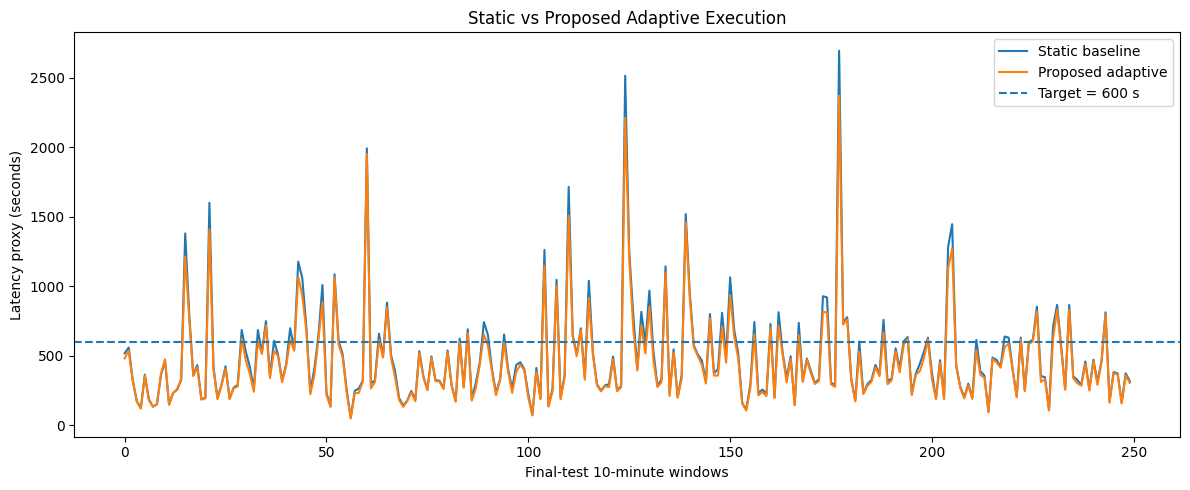

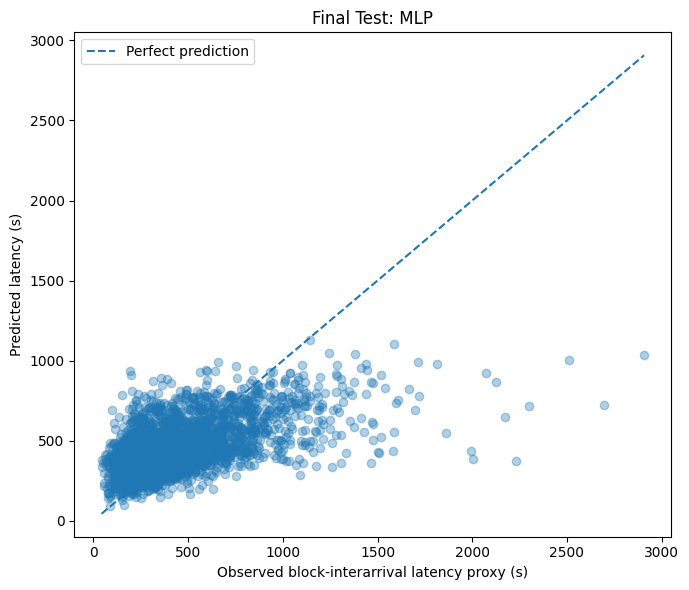

In [24]:
# ============================================================
# 23) VISUALIZATION
# ============================================================

n_plot = min(250, len(test_eval))

plt.figure(figsize=(12, 5))
plt.plot(
    test_eval["static_latency"].values[:n_plot],
    label="Static baseline"
)
plt.plot(
    test_eval["adaptive_latency"].values[:n_plot],
    label="Proposed adaptive"
)
plt.axhline(
    TARGET_LATENCY,
    linestyle="--",
    label="Target = 600 s"
)
plt.xlabel("Final-test 10-minute windows")
plt.ylabel("Latency proxy (seconds)")
plt.title("Static vs Proposed Adaptive Execution")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(
    y_test,
    test_pred,
    alpha=0.35
)
line_min = min(y_test.min(), test_pred.min())
line_max = max(y_test.max(), test_pred.max())
plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--",
    label="Perfect prediction"
)
plt.xlabel("Observed block-interarrival latency proxy (s)")
plt.ylabel("Predicted latency (s)")
plt.title(f"Final Test: {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()


In [25]:
# ============================================================
# 24) FINAL REPRODUCIBILITY / MANUSCRIPT AUDIT
# ============================================================

print("============================================================")
print("FINAL MANUSCRIPT AUDIT")
print("============================================================")

print("Data source:",
      f"{DATASET_PROJECT}.{DATASET}.{TABLE}")
print("Date range:", START_DATE, "to", END_DATE)
print("Aggregation:", f"{WINDOW_MINUTES} minutes")
print("Total usable windows:", len(w))
print("Train windows:", len(train_df))
print("Validation windows:", len(val_df))
print("Final test windows:", len(test_df))

print("\nSelected predictive model:", best_model_name)
print("Final test MAE:", final_test_metrics["MAE"])
print("Final test RMSE:", final_test_metrics["RMSE"])
print("Final test R2:", final_test_metrics["R2"])

print("\nController thresholds selected using validation only:")
for k, v in best_cfg.items():
    print(f"{k}: {v}")

print("\nFinal controller improvements vs static:")
for metric in ["MAE_to_600", "RMSE_to_600", "Variance_around_600"]:
    base = static_m[metric]
    prop = adaptive_m[metric]
    imp = (base - prop) / base * 100
    print(f"{metric}: {imp:.2f}%")

print("\nStatistical analysis:")
print("Paired t-test p:", t_p)
print("Wilcoxon p:", w_p)
print("Cohen's d:", cohen_d)
print("Levene p:", levene_p)

print("\nBootstrap MAE improvement:")
print(f"{point_improvement:.2f}% "
      f"(95% CI {ci_low:.2f}% to {ci_high:.2f}%)")

print("\nIMPORTANT INTERPRETATION:")
print("- Final-test prediction metrics are genuinely out-of-sample.")
print("- Controller gains are trace-driven simulation results.")
print("- Storage saving is a simulated allocation estimate.")
print("- The latency target is a design target of 600 s.")
print("- The target is a block-interarrival/confirmation-latency proxy,")
print("  not direct transaction-level confirmation latency.")
print("- Do NOT copy any previous manuscript percentages into the paper")
print("  until this notebook finishes and the final audit is recorded.")


FINAL MANUSCRIPT AUDIT
Data source: bigquery-public-data.crypto_bitcoin.blocks
Date range: 2020-01-01 to 2021-01-01
Aggregation: 10 minutes
Total usable windows: 14235
Train windows: 9110
Validation windows: 2278
Final test windows: 2847

Selected predictive model: MLP
Final test MAE: 164.7788737501822
Final test RMSE: 239.50909658474907
Final test R2: 0.3315658038408654

Controller thresholds selected using validation only:
lower_threshold: 450.0
upper_threshold: 624.0
queue_threshold: 0.4
storage_threshold: 0.4
validation_activation_rate: 0.9973661106233538
validation_objective: 67824.25805340103

Final controller improvements vs static:
MAE_to_600: 0.88%
RMSE_to_600: 3.18%
Variance_around_600: 17.86%

Statistical analysis:
Paired t-test p: 0.003026070026370024
Wilcoxon p: 1.2186975835506958e-53
Cohen's d: 0.055618074863607106
Levene p: 0.09806372310821092

Bootstrap MAE improvement:
0.88% (95% CI 0.31% to 1.45%)

IMPORTANT INTERPRETATION:
- Final-test prediction metrics are genuinel

In [26]:
# ============================================================
# 25) SAVE FINAL RESULT TABLES
# ============================================================

OUTPUT_DIR = "/content/final_reviewer_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

validation_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation_model_comparison.csv"),
    index=False
)

controller_summary.to_csv(
    os.path.join(OUTPUT_DIR, "controller_comparison.csv"),
    index=False
)

test_eval.to_csv(
    os.path.join(OUTPUT_DIR, "final_test_window_results.csv"),
    index=False
)

if not repeat_df.empty:
    repeat_df.to_csv(
        os.path.join(OUTPUT_DIR, "repeated_runs.csv"),
        index=False
    )

audit = {
    "data_source": f"{DATASET_PROJECT}.{DATASET}.{TABLE}",
    "start_date": START_DATE,
    "end_date": END_DATE,
    "aggregation_minutes": WINDOW_MINUTES,
    "train_windows": len(train_df),
    "validation_windows": len(val_df),
    "test_windows": len(test_df),
    "selected_model": best_model_name,
    "final_test_mae": final_test_metrics["MAE"],
    "final_test_rmse": final_test_metrics["RMSE"],
    "final_test_r2": final_test_metrics["R2"],
    "controller_thresholds": best_cfg,
    "mae_improvement_pct": point_improvement,
    "mae_bootstrap_ci_low": ci_low,
    "mae_bootstrap_ci_high": ci_high,
    "paired_t_p": float(t_p),
    "wilcoxon_p": float(w_p) if np.isfinite(w_p) else None,
    "cohen_d": float(cohen_d),
    "levene_p": float(levene_p)
}

with open(
    os.path.join(OUTPUT_DIR, "final_audit.json"),
    "w"
) as f:
    json.dump(audit, f, indent=2, default=str)

print("Saved final result files to:", OUTPUT_DIR)


Saved final result files to: /content/final_reviewer_results
